## Setup

In [4]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.datasets import make_blobs
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from pyod.utils.data import generate_data_clusters
from pyod.utils.utility import standardizer
from pyod.models.combination import average, maximization
 
rng = np.random.default_rng(0)


## Exercise 1 - Leverage scores

In [5]:
def leverage_scores(X):
    Xb = np.column_stack([X, np.ones(len(X))])
    H = Xb @ np.linalg.pinv(Xb.T @ Xb) @ Xb.T
    return np.diag(H)

def make_points(d, n, coef, b, mu, sigma2, big=5.0):
    """groups: 0 regular, 1 high var x, 2 high var y, 3 high var x and y"""
    coef = np.array(coef); s = np.sqrt(sigma2)
    Xs, ys, gs = [], [], []
    for g, (nn, sx, sy) in enumerate([(n, 1.0, s), (5, big, s),
                                      (5, 1.0, big*s + 1), (5, big, big*s + 1)]):
        X = rng.normal(0, sx, (nn, d))
        y = X @ coef + b + rng.normal(mu, sy, nn)
        Xs.append(X); ys.append(y); gs.append(np.full(nn, g))
    return np.vstack(Xs), np.concatenate(ys), np.concatenate(gs)

names = ["regular", "high var x", "high var y", "high var x & y"]
cols  = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
settings = [(0, 0.05), (0, 0.5), (1, 1.0)]   # (mu, sigma^2)
top_k = 8

mu=0, s2=0.05: {'regular': np.float64(0.011), 'high var x': np.float64(0.075), 'high var y': np.float64(0.013), 'high var x & y': np.float64(0.083)}
mu=0, s2=0.5: {'regular': np.float64(0.013), 'high var x': np.float64(0.106), 'high var y': np.float64(0.013), 'high var x & y': np.float64(0.027)}
mu=1, s2=1.0: {'regular': np.float64(0.011), 'high var x': np.float64(0.114), 'high var y': np.float64(0.01), 'high var x & y': np.float64(0.059)}


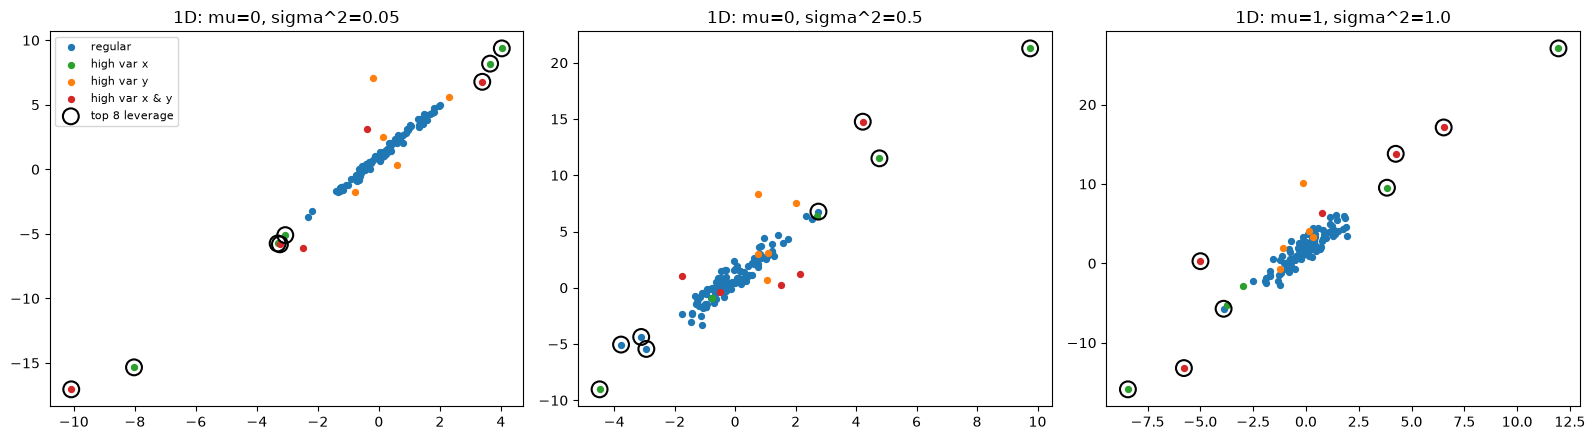

In [6]:
fig, axs = plt.subplots(1, len(settings), figsize=(16, 4.5))
for ax, (mu, s2) in zip(axs, settings):
    X, y, g = make_points(1, 100, [2.0], 1.0, mu, s2)
    h = leverage_scores(X)
    for k in range(4):
        ax.scatter(X[g==k, 0], y[g==k], c=cols[k], s=18, label=names[k])
    top = np.argsort(h)[-top_k:]
    ax.scatter(X[top, 0], y[top], s=130, facecolors="none", edgecolors="k", linewidths=1.5, label=f"top {top_k} leverage")
    ax.set_title(f"1D: mu={mu}, sigma^2={s2}")
    print(f"mu={mu}, s2={s2}:", {names[k]: round(h[g==k].mean(), 3) for k in range(4)})
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

mu=0, s2=0.05: {'regular': np.float64(0.014), 'high var x': np.float64(0.138), 'high var y': np.float64(0.011), 'high var x & y': np.float64(0.164)}
mu=0, s2=0.5: {'regular': np.float64(0.014), 'high var x': np.float64(0.173), 'high var y': np.float64(0.019), 'high var x & y': np.float64(0.12)}
mu=1, s2=1.0: {'regular': np.float64(0.014), 'high var x': np.float64(0.186), 'high var y': np.float64(0.013), 'high var x & y': np.float64(0.12)}


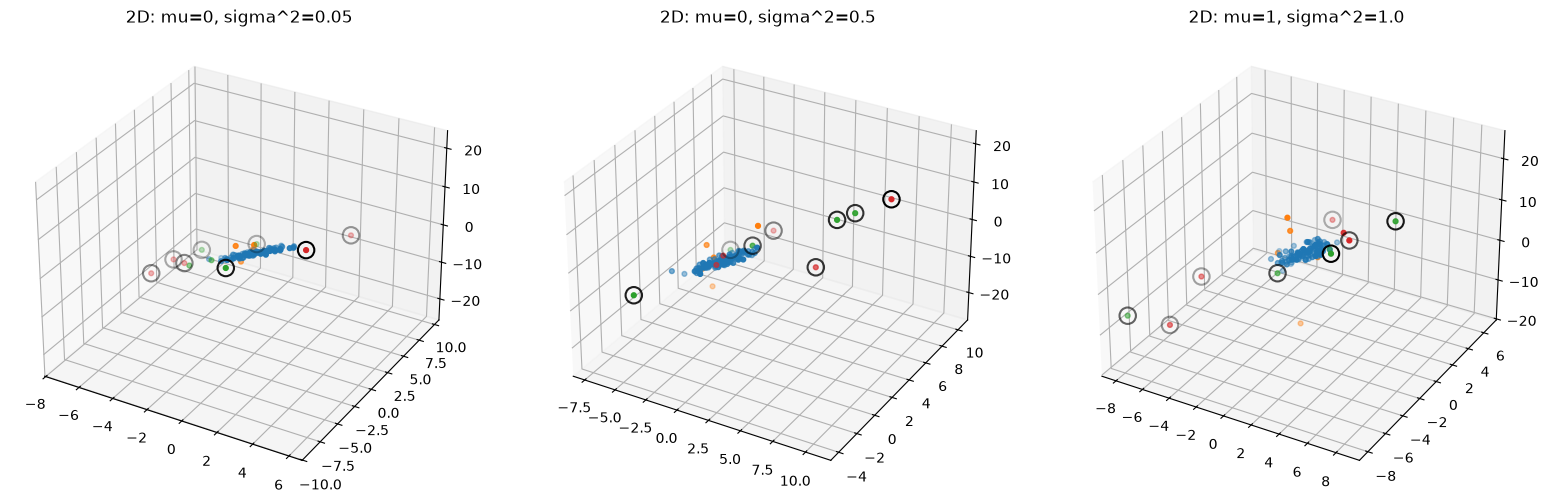

In [7]:
fig = plt.figure(figsize=(16, 5))
for i, (mu, s2) in enumerate(settings):
    ax = fig.add_subplot(1, len(settings), i+1, projection="3d")
    X, y, g = make_points(2, 100, [2.0, -1.0], 1.0, mu, s2)
    h = leverage_scores(X)
    for k in range(4):
        ax.scatter(X[g==k, 0], X[g==k, 1], y[g==k], c=cols[k], s=12, label=names[k])
    top = np.argsort(h)[-top_k:]
    ax.scatter(X[top, 0], X[top, 1], y[top], s=140, facecolors="none", edgecolors="k", linewidths=1.5)
    ax.set_title(f"2D: mu={mu}, sigma^2={s2}")
    print(f"mu={mu}, s2={s2}:", {names[k]: round(h[g==k].mean(), 3) for k in range(4)})
plt.tight_layout(); plt.show()

## Exercise 2 - KNN on `generate_data_clusters`

n_neighbors=  1  BA train=0.879  BA test=0.904


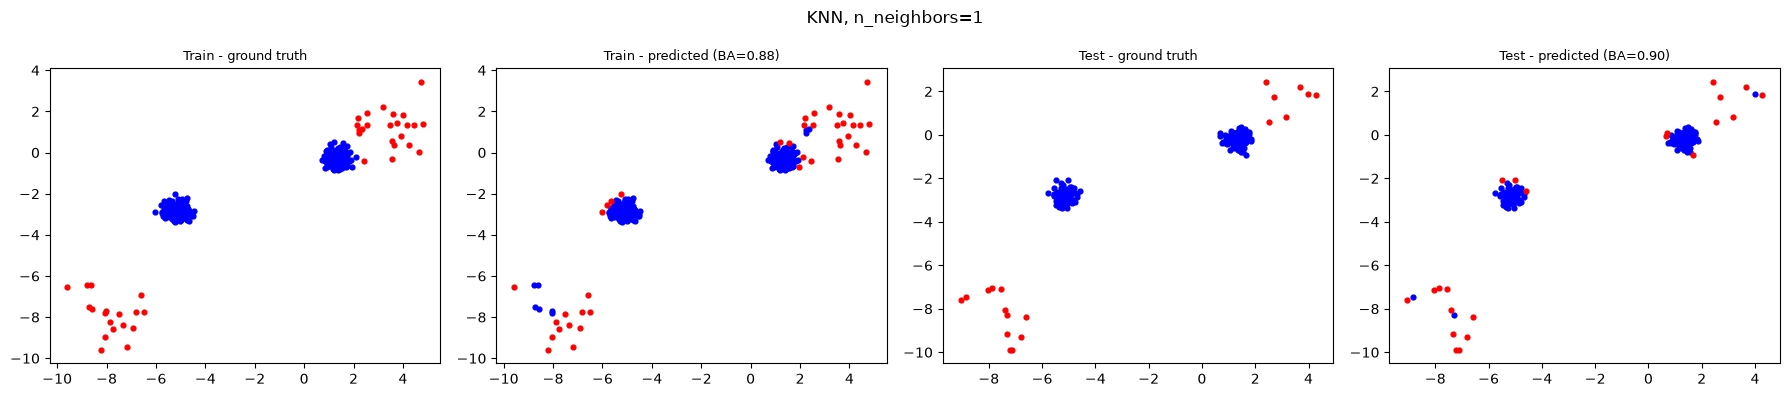

n_neighbors=  5  BA train=0.988  BA test=1.000


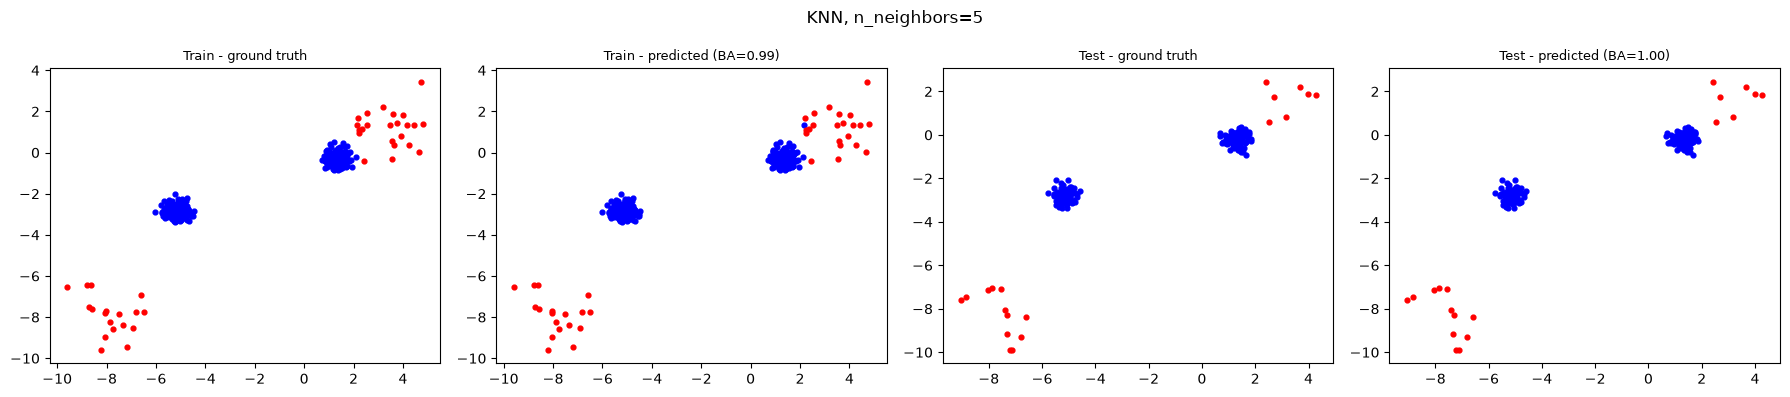

n_neighbors= 10  BA train=0.988  BA test=1.000


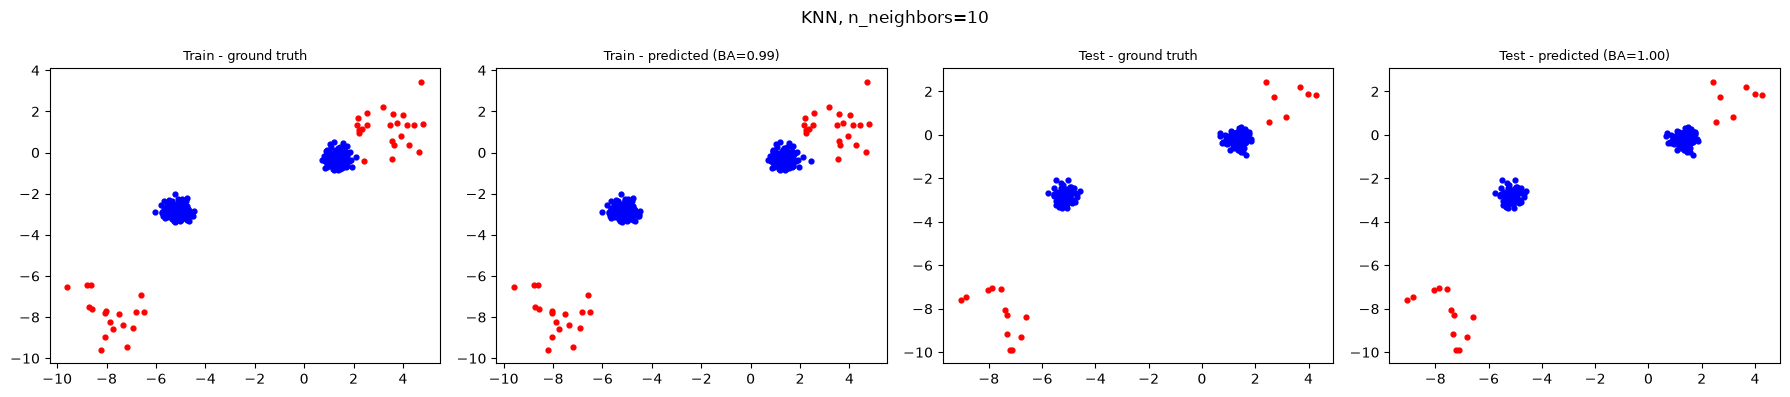

n_neighbors= 20  BA train=0.988  BA test=1.000


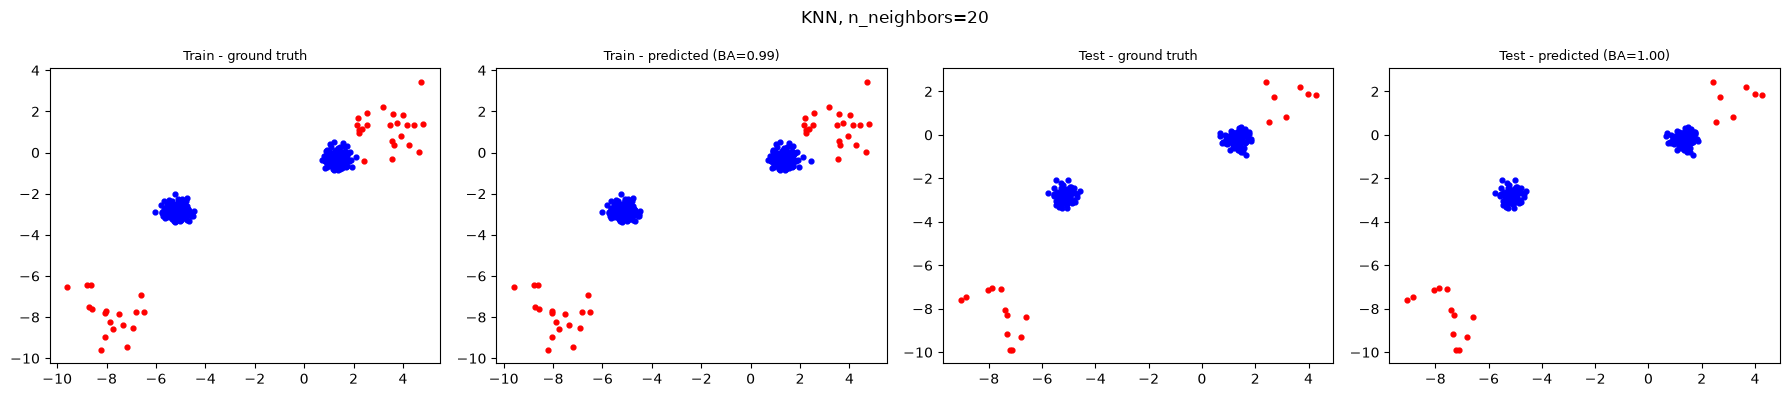

n_neighbors= 40  BA train=0.988  BA test=1.000


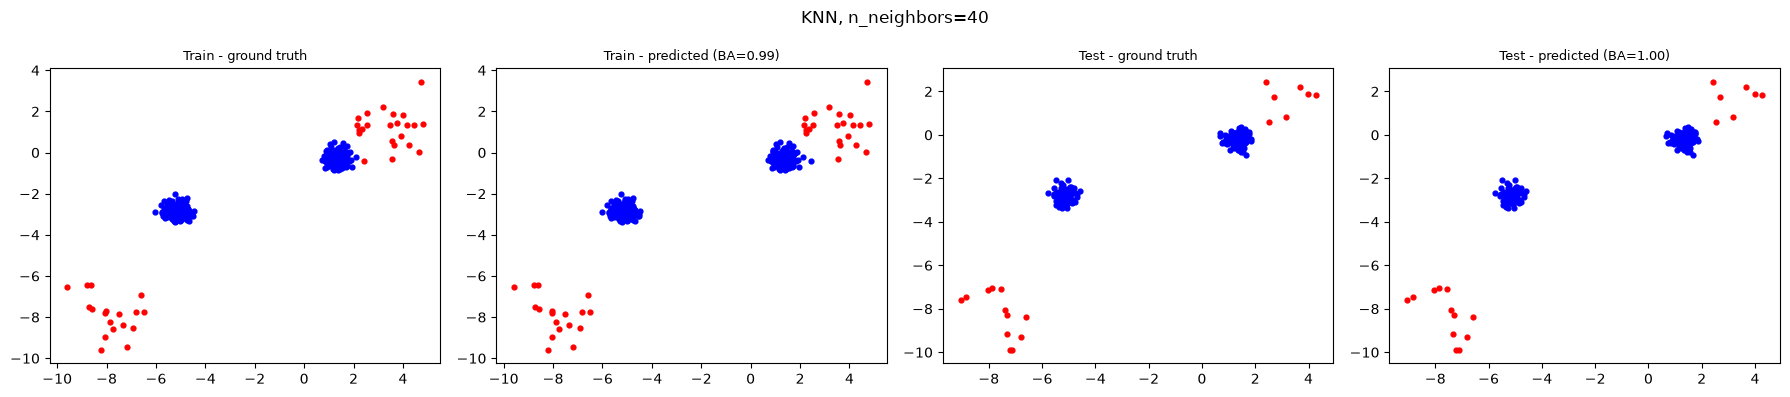

In [8]:
X_train, X_test, y_train, y_test = generate_data_clusters(
    n_train=400, n_test=200, n_clusters=2, n_features=2,
    contamination=0.1, random_state=42)

def scat(ax, X, y, title):
    ax.scatter(X[y==0, 0], X[y==0, 1], c="blue", s=12, label="inlier")
    ax.scatter(X[y==1, 0], X[y==1, 1], c="red",  s=12, label="outlier")
    ax.set_title(title, fontsize=9)

for k in [1, 5, 10, 20, 40]:
    clf = KNN(contamination=0.1, n_neighbors=k).fit(X_train)
    y_train_pred = clf.labels_
    y_test_pred  = clf.predict(X_test)
    ba_tr = balanced_accuracy_score(y_train, y_train_pred)
    ba_te = balanced_accuracy_score(y_test,  y_test_pred)
    print(f"n_neighbors={k:3d}  BA train={ba_tr:.3f}  BA test={ba_te:.3f}")

    fig, axs = plt.subplots(1, 4, figsize=(18, 4))
    scat(axs[0], X_train, y_train,      "Train - ground truth")
    scat(axs[1], X_train, y_train_pred, f"Train - predicted (BA={ba_tr:.2f})")
    scat(axs[2], X_test,  y_test,       "Test - ground truth")
    scat(axs[3], X_test,  y_test_pred,  f"Test - predicted (BA={ba_te:.2f})")
    fig.suptitle(f"KNN, n_neighbors={k}")
    plt.tight_layout(); plt.show()

### Exercise 3 - KNN vs LOF with different densities

KNN k=5: outliers in dense cluster=9, in sparse cluster=12
LOF k=5: outliers in dense cluster=13, in sparse cluster=8
KNN k=20: outliers in dense cluster=11, in sparse cluster=10
LOF k=20: outliers in dense cluster=16, in sparse cluster=5
KNN k=50: outliers in dense cluster=12, in sparse cluster=9
LOF k=50: outliers in dense cluster=16, in sparse cluster=5


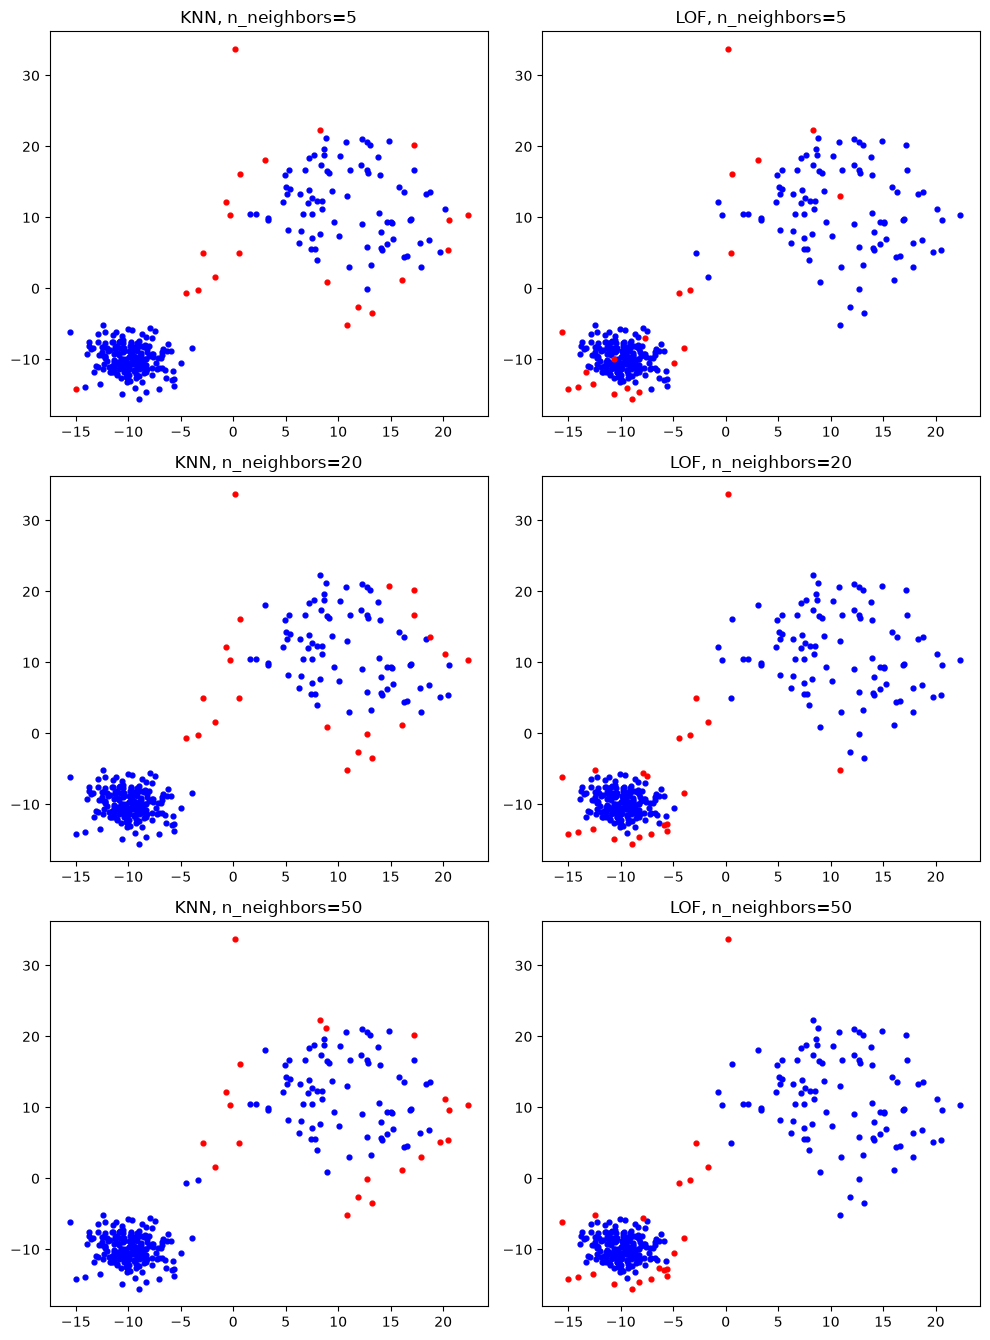

In [9]:
X, _ = make_blobs(n_samples=[200, 100], centers=[(-10, -10), (10, 10)],
                  cluster_std=[2, 6], n_features=2, random_state=1)

neighbors = [5, 20, 50]
fig, axs = plt.subplots(len(neighbors), 2, figsize=(10, 4.5*len(neighbors)))
for i, k in enumerate(neighbors):
    for j, (name, Model) in enumerate([("KNN", KNN), ("LOF", LOF)]):
        clf = Model(contamination=0.07, n_neighbors=k).fit(X)
        y = clf.labels_
        ax = axs[i, j]
        ax.scatter(X[y==0, 0], X[y==0, 1], c="blue", s=12)
        ax.scatter(X[y==1, 0], X[y==1, 1], c="red",  s=12)
        ax.set_title(f"{name}, n_neighbors={k}")
        print(f"{name} k={k}: outliers in dense cluster={y[:200].sum()}, in sparse cluster={y[200:].sum()}")
plt.tight_layout(); plt.show()

### Exercise 4 - Ensemble of KNN / LOF on `cardio`

In [10]:
data = loadmat("cardio.mat")
X, y = data["X"], data["y"].ravel()
contamination = y.mean()
print(X.shape, "contamination =", round(contamination, 4))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)
X_train, X_test = standardizer(X_train, X_test)   # fit on train, applied to both

(1831, 21) contamination = 0.0961


In [11]:
def run_ensemble(Model, ks):
    train_scores = np.zeros((len(X_train), len(ks)))
    test_scores  = np.zeros((len(X_test),  len(ks)))
    for i, k in enumerate(ks):
        clf = Model(n_neighbors=int(k), contamination=contamination).fit(X_train)
        train_scores[:, i] = clf.decision_scores_
        test_scores[:, i]  = clf.decision_function(X_test)
        ba_tr = balanced_accuracy_score(y_train, clf.labels_)
        ba_te = balanced_accuracy_score(y_test,  clf.predict(X_test))
        print(f"  n_neighbors={k:3d}  BA train={ba_tr:.3f}  BA test={ba_te:.3f}")

    train_norm, test_norm = standardizer(train_scores, test_scores)
    for name, combine in [("average", average), ("maximization", maximization)]:
        tr, te = combine(train_norm), combine(test_norm)
        pred_tr = (tr > np.quantile(tr, 1 - contamination)).astype(int)
        pred_te = (te > np.quantile(te, 1 - contamination)).astype(int)
        print(f"  [{name}] BA train={balanced_accuracy_score(y_train, pred_tr):.3f}  "
              f"BA test={balanced_accuracy_score(y_test, pred_te):.3f}")

ks = np.linspace(30, 120, 10, dtype=int)
print("KNN"); run_ensemble(KNN, ks)

KNN
  n_neighbors= 30  BA train=0.713  BA test=0.662
  n_neighbors= 40  BA train=0.723  BA test=0.670
  n_neighbors= 50  BA train=0.734  BA test=0.677
  n_neighbors= 60  BA train=0.749  BA test=0.700
  n_neighbors= 70  BA train=0.755  BA test=0.728
  n_neighbors= 80  BA train=0.765  BA test=0.729
  n_neighbors= 90  BA train=0.760  BA test=0.715
  n_neighbors=100  BA train=0.765  BA test=0.722
  n_neighbors=110  BA train=0.770  BA test=0.722
  n_neighbors=120  BA train=0.770  BA test=0.715
  [average] BA train=0.755  BA test=0.747
  [maximization] BA train=0.755  BA test=0.762


In [12]:
print("LOF"); run_ensemble(LOF, ks)

LOF
  n_neighbors= 30  BA train=0.535  BA test=0.565
  n_neighbors= 40  BA train=0.546  BA test=0.546
  n_neighbors= 50  BA train=0.551  BA test=0.553
  n_neighbors= 60  BA train=0.577  BA test=0.567
  n_neighbors= 70  BA train=0.624  BA test=0.595
  n_neighbors= 80  BA train=0.645  BA test=0.620
  n_neighbors= 90  BA train=0.661  BA test=0.628
  n_neighbors=100  BA train=0.676  BA test=0.637
  n_neighbors=110  BA train=0.687  BA test=0.668
  n_neighbors=120  BA train=0.702  BA test=0.682
  [average] BA train=0.619  BA test=0.612
  [maximization] BA train=0.650  BA test=0.636
